In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
wine = load_wine()

X = wine.data
y = wine.target

print("Features Shape :", X.shape)
print("Labels Shape :", y.shape)

Features Shape : (178, 13)
Labels Shape : (178,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
def create_model(lr):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(13,)),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(3, activation='softmax')
    ])
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

In [ ]:
learning_rates = [0.1, 0.01, 0.001]
lr_results = {}
for lr in learning_rates:
    print("\nTraining with Learning Rate =", lr)
    model = create_model(lr)
    history = model.fit(

        X_train,
        y_train,

        validation_data=(X_test, y_test),
        epochs=50,
        verbose=0
    )
    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
    lr_results[lr] = accuracy
    print("Test Accuracy =", accuracy)


Training with Learning Rate = 0.1


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Test Accuracy = 1.0

Training with Learning Rate = 0.01
Test Accuracy = 1.0

Training with Learning Rate = 0.001
Test Accuracy = 1.0


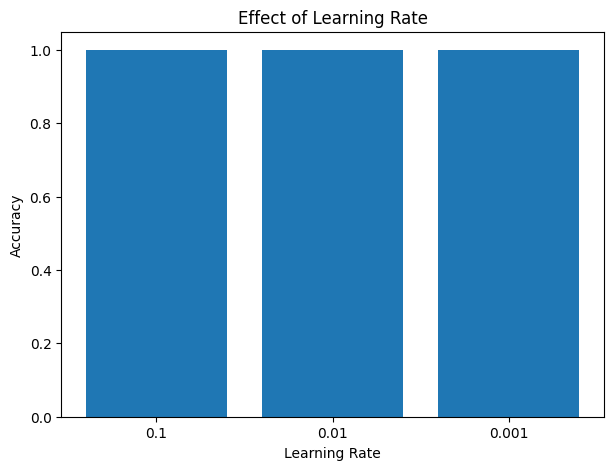

In [ ]:
plt.figure(figsize=(7,5))

plt.bar(
    [str(i) for i in lr_results.keys()],
    lr_results.values()
)

plt.xlabel("Learning Rate")
plt.ylabel("Accuracy")
plt.title("Effect of Learning Rate")

plt.show()

In [ ]:
epochs_list = [5,10,20]

epoch_results = {}

for ep in epochs_list:
    print("\nTraining for", ep, "epochs")
    model = create_model(0.001)

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_test, y_test),
        epochs=ep,
        verbose=0
    )

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
    epoch_results[ep] = accuracy
    print("Accuracy =", accuracy)


Training for 5 epochs
Accuracy = 0.9444444179534912

Training for 10 epochs
Accuracy = 1.0

Training for 20 epochs
Accuracy = 1.0


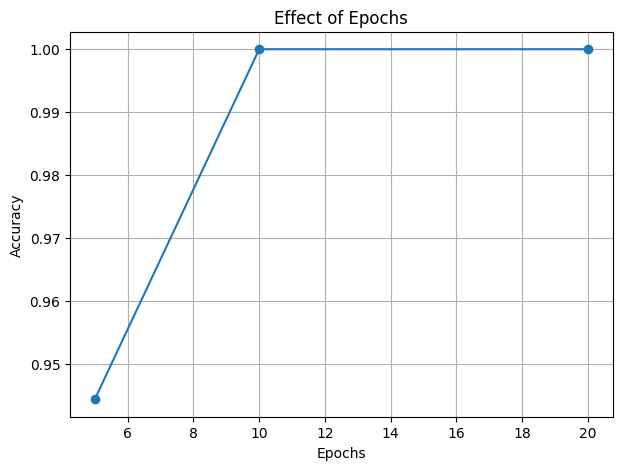

In [ ]:
plt.figure(figsize=(7,5))

plt.plot(
    list(epoch_results.keys()),
    list(epoch_results.values()),
    marker='o'
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Effect of Epochs")

plt.grid()

plt.show()

In [ ]:
model = create_model(0.001)
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=20,
    verbose=1
)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 120ms/step - accuracy: 0.6197 - loss: 1.0092 - val_accuracy: 0.8333 - val_loss: 0.8942
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.8944 - loss: 0.8274 - val_accuracy: 1.0000 - val_loss: 0.7183
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9789 - loss: 0.6557 - val_accuracy: 1.0000 - val_loss: 0.5442
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9789 - loss: 0.4939 - val_accuracy: 1.0000 - val_loss: 0.3869
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9859 - loss: 0.3526 - val_accuracy: 1.0000 - val_loss: 0.2564
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9930 - loss: 0.2391 - val_accuracy: 1.0000 - val_loss: 0.1643
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9930 - loss: 0.1592 - val_accuracy: 1.0000 - val_loss: 0.1044
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9930 - loss: 0.1070 - val_accuracy: 1.0000 - val_loss: 0.0683

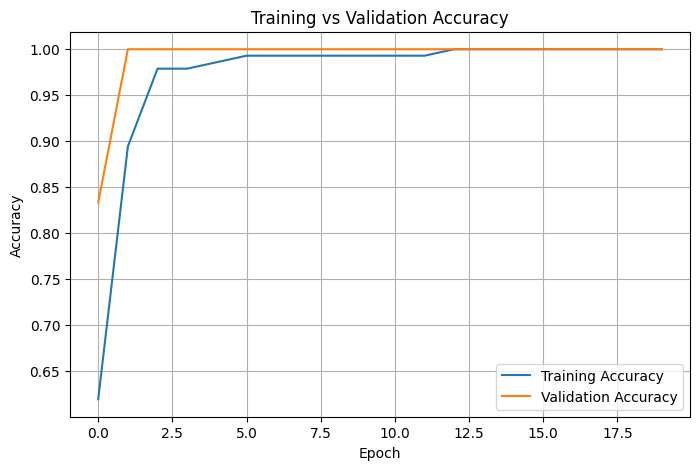

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title("Training vs Validation Accuracy")

plt.legend()

plt.grid()

plt.show()

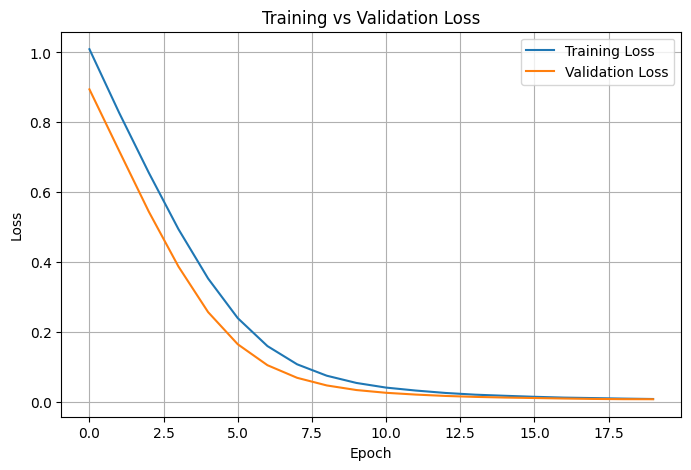

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Training vs Validation Loss")

plt.legend()

plt.grid()

plt.show()

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Final Test Accuracy :", accuracy)
print("Final Test Loss :", loss)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 1.0000 - loss: 0.0070
Final Test Accuracy : 1.0
Final Test Loss : 0.0070089600048959255


In [ ]:
lr_df = pd.DataFrame({
    "Learning Rate": list(lr_results.keys()),
    "Accuracy": list(lr_results.values())

})

print("Learning Rate Comparison")
print(lr_df)
print()

epoch_df = pd.DataFrame({

    "Epochs": list(epoch_results.keys()),
    "Accuracy": list(epoch_results.values())
})
print("Epoch Comparison")
print(epoch_df)

Learning Rate Comparison
   Learning Rate  Accuracy
0          0.100       1.0
1          0.010       1.0
2          0.001       1.0

Epoch Comparison
   Epochs  Accuracy
0       5  0.944444
1      10  1.000000
2      20  1.000000
